Generation: 1 Best Fitness: 0.5
Generation: 2 Best Fitness: 0.5
Generation: 3 Best Fitness: 0.5
Generation: 4 Best Fitness: 0.5
Generation: 5 Best Fitness: 0.5
Generation: 6 Best Fitness: 0.5
Generation: 7 Best Fitness: 0.5
Generation: 8 Best Fitness: 0.5
Generation: 9 Best Fitness: 0.5
Generation: 10 Best Fitness: 0.5
Generation: 11 Best Fitness: 0.5
Generation: 12 Best Fitness: 0.5
Generation: 13 Best Fitness: 0.5
Generation: 14 Best Fitness: 0.5
Generation: 15 Best Fitness: 0.5
Generation: 16 Best Fitness: 0.5
Generation: 17 Best Fitness: 0.5
Generation: 18 Best Fitness: 0.5
Generation: 19 Best Fitness: 0.5
Generation: 20 Best Fitness: 0.5
Generation: 21 Best Fitness: 0.5
Generation: 22 Best Fitness: 0.5
Generation: 23 Best Fitness: 1.0
Generation: 24 Best Fitness: 1.0
Generation: 25 Best Fitness: 1.0
Generation: 26 Best Fitness: 1.0
Generation: 27 Best Fitness: 1.0
Generation: 28 Best Fitness: 1.0
Generation: 29 Best Fitness: 1.0
Generation: 30 Best Fitness: 1.0
Generation: 31 Best

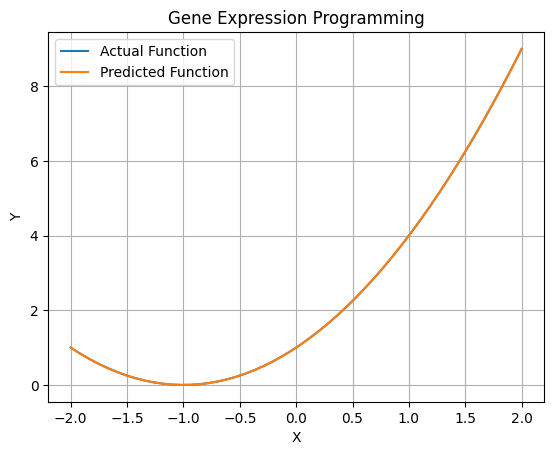

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

head_length = 5
tail_length = 6
population_size = 40
generations = 60
mutation_rate = 0.1

operators = ['+', '-', '*', '/']
terminals = ['x', '1', '2', '3']
symbols = operators + terminals

x = np.linspace(-2, 2, 50)
y = x**2 + 2*x + 1

def create_chromosome():
    head = [random.choice(symbols) for _ in range(head_length)]
    tail = [random.choice(terminals) for _ in range(tail_length)]
    return head + tail

def build_tree(chromosome, index=0):
    token = chromosome[index]

    if token in operators:
        left, index = build_tree(chromosome, index + 1)
        right, index = build_tree(chromosome, index)
        return (token, left, right), index

    return token, index + 1

def evaluate_tree(tree, x):
    if isinstance(tree, str):
        if tree == 'x':
            return x
        return np.full_like(x, float(tree))

    op, left, right = tree

    a = evaluate_tree(left, x)
    b = evaluate_tree(right, x)

    if op == '+':
        return a + b
    elif op == '-':
        return a - b
    elif op == '*':
        return a * b
    else:
        return np.where(np.abs(b) < 1e-6, a, a / np.where(np.abs(b) < 1e-6, 1, b))

def expression(tree):
    if isinstance(tree, str):
        return tree

    op, left, right = tree

    return "(" + expression(left) + op + expression(right) + ")"

def fitness(chromosome):
    tree, _ = build_tree(chromosome)
    prediction = evaluate_tree(tree, x)

    error = np.mean((y - prediction) ** 2)

    return 1 / (1 + error)

population = [
    create_chromosome()
    for _ in range(population_size)
]

best_chromosome = None
best_fitness = -1

for generation in range(generations):

    scores = np.array([fitness(c) for c in population])

    best_index = np.argmax(scores)

    if scores[best_index] > best_fitness:
        best_fitness = scores[best_index]
        best_chromosome = population[best_index].copy()

    new_population = [best_chromosome.copy()]

    while len(new_population) < population_size:

        parents = np.random.choice(
            population_size, 2, replace=False
        )

        parent1 = population[parents[0]].copy()
        parent2 = population[parents[1]].copy()

        point = random.randint(1, head_length - 1)

        child = (
            parent1[:point] +
            parent2[point:head_length] +
            parent1[head_length:]
        )

        for i in range(head_length):
            if random.random() < mutation_rate:
                child[i] = random.choice(symbols)

        for i in range(head_length, head_length + tail_length):
            if random.random() < mutation_rate:
                child[i] = random.choice(terminals)

        new_population.append(child)

    population = new_population

    print("Generation:", generation + 1,
          "Best Fitness:", round(best_fitness, 6))

best_tree, _ = build_tree(best_chromosome)

print("Best Chromosome:", best_chromosome)
print("Best Expression:", expression(best_tree))
print("Best Fitness:", best_fitness)

prediction = evaluate_tree(best_tree, x)

plt.plot(x, y, label="Actual Function")
plt.plot(x, prediction, label="Predicted Function")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Gene Expression Programming")
plt.legend()
plt.grid()
plt.show()
